# CorroVision - Final Pipeline (Weeks 9-11)
### Marine corrosion detection (Stage 1) and corrosion-type classification (Stage 2)

Continues from Parts 1-5. It uses the shared `processed_images.csv` (same 70/15/15 split) and:

1. rebuilds the processed images and the HOG / GLCM features, and proves they match the retained `features_test.npz`
2. retrains HOG + SVM and GLCM + Random Forest, and adds the Colour-Texture extension
3. scores the Part 5 baseline CNN (Stage 1) and trains a deeper CNN for Stage 2
4. transfer learning with ResNet50: phase 1 (frozen backbone) and phase 2 (fine-tuning conv5); then ConvNeXt / EfficientNetV2 features, fusion and TTA
5. final evaluation: metrics, threshold tuning, McNemar's test, end-to-end pipeline, all figures

**Run the cells top to bottom.** A GPU runtime is recommended for steps 3-4 (they also run on CPU; about 2.5 hours).
Put these files in one Drive folder and set `INPUT_DIR` below: `processed_images.csv`, `features_test.npz`,
and a `part5/` folder with `best_cnn_stage1.keras` and `cnn_test_predictions.csv`.

In [ ]:
# scikit-learn is pinned: Random Forest results change between versions, and 1.6.1 is the
# version that produced the progress-report numbers.
!pip -q install kagglehub opencv-python-headless scikit-image "scikit-learn==1.6.1" joblib scipy

import os, shutil
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

INPUT_DIR = Path('/content/drive/MyDrive/corrovision_inputs')     # <- change if needed
ROOT = Path('/content/corrovision')
(ROOT / 'code').mkdir(parents=True, exist_ok=True)
if not (ROOT / 'inputs').exists():
    shutil.copytree(INPUT_DIR, ROOT / 'inputs')
os.environ['CORRO_ROOT'] = str(ROOT)

import kagglehub
os.environ['CORRO_DATA'] = kagglehub.dataset_download('ebrahim007/marine-corrosion-dataset')
print('Dataset:', os.environ['CORRO_DATA'])
%cd /content/corrovision/code

## Shared configuration and the unchanged Part 2 functions

In [ ]:
%%writefile common.py
"""CorroVision - shared configuration and helpers (Parts 6-9, Weeks 9-11).

Everything here reuses the team's earlier decisions unchanged:
the 70/15/15 split and labels come from `processed_images.csv` (Part 2),
and the preprocessing / augmentation / HOG / GLCM functions are copied from Part 2.
"""
import os, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2

SEED = 42
IMG_SIZE = 224
random.seed(SEED); np.random.seed(SEED)

ROOT = Path(os.environ.get('CORRO_ROOT', Path(__file__).resolve().parent.parent))
IN_DIR = ROOT / 'inputs'                      # processed_images.csv, features_test.npz, part5/
WORK = ROOT / 'work'                          # regenerated images, features, cached activations
OUT = ROOT / 'outputs'                        # predictions, metrics, figures
FIG = OUT / 'figures'
PROC_DIR = WORK / 'processed'
for d in (WORK, OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

HEALTHY = 'healthy_structure'
S1_NAMES = ['Healthy', 'Corroded']
S2_CLASSES = ['crevice_corrosion', 'erosion_corrosion', 'galvanic_corrosion', 'mic_corrosion',
              'pitting_corrosion', 'stress_corrosion', 'under_insulation_corrosion', 'uniform_corrosion']
ALL9 = [HEALTHY] + S2_CLASSES


def nice(c):
    return (c.replace('_corrosion', '').replace('_structure', '').replace('_', ' ')
             .title().replace('Mic', 'MIC'))


S2_NAMES = [nice(c) for c in S2_CLASSES]
ALL9_NAMES = [nice(c) for c in ALL9]


def load_manifest():
    """Shared manifest written by Part 2 (one row per processed image)."""
    m = pd.read_csv(IN_DIR / 'processed_images.csv', keep_default_na=False)
    m['is_aug'] = m['is_aug'].astype(str).str.lower().map({'true': True, 'false': False})
    # Part 2 named every file after the image's position in the clean dataframe
    # (train/<class>/00001.png, train_aug/<class>/00001_aug1.png), so the index that
    # seeded the augmentation (SEED + idx) can be read back from the file name.
    m['idx'] = m['processed_path'].map(lambda p: int(Path(p).stem.split('_')[0]))
    assert set(m['split']) == {'train', 'val', 'test'}
    assert m.loc[m['split'] != 'train', 'is_aug'].eq(False).all()
    return m


# ----------------------------------------------------------------------------- Part 2 (unchanged)
def load_rgb(path):
    im = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if im is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)


def resize(rgb):
    return cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)


def denoise(rgb):
    return cv2.bilateralFilter(rgb, 5, 20, 3)


def color_correct(rgb, gain_range=(0.5, 3.0)):
    x = rgb.astype(np.float32)
    means = x.reshape(-1, 3).mean(axis=0) + 1e-6
    gains = np.clip(means.mean() / means, *gain_range)
    return np.clip(x * gains, 0, 255).astype(np.uint8)


def enhance_contrast(rgb, clip=2.0, grid=(8, 8)):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def preprocess(rgb):
    return enhance_contrast(color_correct(denoise(resize(rgb))))


def to_unit(rgb_uint8):
    return rgb_uint8.astype(np.float32) / 255.0


def augment(rgb_uint8, rng):
    img = to_unit(rgb_uint8)
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), rng.uniform(-30, 30), 1.0)
    img = cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_REFLECT_101)
    if rng.random() < 0.5: img = img[:, ::-1]
    if rng.random() < 0.5: img = img[::-1, :]
    img = np.clip(img * rng.uniform(0.7, 1.3) + rng.uniform(-0.08, 0.08), 0, 1)
    return (img * 255).round().astype(np.uint8)


HOG_ORIENT, HOG_PPC, HOG_CPB = 9, (16, 16), (2, 2)
GLCM_LEVELS, GLCM_DIST, GLCM_ANGLES = 32, [1, 2, 4], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
GLCM_PROPS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'ASM', 'correlation', 'entropy']


def hog_features(rgb_uint8):
    from skimage.feature import hog
    gray = cv2.cvtColor(to_unit(rgb_uint8), cv2.COLOR_RGB2GRAY)
    return hog(gray, orientations=HOG_ORIENT, pixels_per_cell=HOG_PPC,
               cells_per_block=HOG_CPB, block_norm='L2-Hys').astype(np.float32)


def glcm_features(rgb_uint8):
    from skimage.feature import graycomatrix, graycoprops
    gray = cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2GRAY)
    q = (gray.astype(np.uint16) * GLCM_LEVELS // 256).astype(np.uint8)
    P = graycomatrix(q, GLCM_DIST, GLCM_ANGLES, levels=GLCM_LEVELS, symmetric=True, normed=True)
    feats = [graycoprops(P, p).ravel() for p in GLCM_PROPS if p != 'entropy']
    feats.append(-np.sum(P * np.log2(P + 1e-12), axis=(0, 1)).ravel())
    return np.concatenate(feats).astype(np.float32)


# ----------------------------------------------------------------------------- new in Part 6
def color_lbp_features(rgb_uint8):
    """Extension proposed in the progress report: colour + LBP texture (92 values).

    HSV histograms (32 hue + 16 saturation + 16 value bins) describe colour, which
    neither HOG nor GLCM uses; uniform LBP histograms at two radii describe micro-texture.
    """
    from skimage.feature import local_binary_pattern
    hsv = cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2HSV)
    n = hsv.shape[0] * hsv.shape[1]
    feats = [np.bincount((hsv[..., 0].ravel().astype(np.int32) * 32) // 180, minlength=32)[:32] / n,
             np.bincount(hsv[..., 1].ravel() // 16, minlength=16) / n,
             np.bincount(hsv[..., 2].ravel() // 16, minlength=16) / n]
    gray = cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2GRAY)
    for P, R in ((8, 1), (16, 2)):
        lbp = local_binary_pattern(gray, P, R, method='uniform').astype(np.int32)
        feats.append(np.bincount(lbp.ravel(), minlength=P + 2) / n)
    return np.concatenate(feats).astype(np.float32)


# ----------------------------------------------------------------------------- data access
def split_frame(m, split):
    return m[m['split'] == split].reset_index(drop=True)


def load_images(split):
    """uint8 array (N, 224, 224, 3) written by 01_regenerate.py, in manifest order."""
    return np.load(WORK / f'images_{split}.npy', mmap_mode='r')


def labels(m, split):
    s = split_frame(m, split)
    y1 = (s['stage1'] == 'Corroded').astype(np.int64).to_numpy()            # 0 Healthy, 1 Corroded
    y2 = s['stage2'].map({c: i for i, c in enumerate(S2_CLASSES)}).fillna(-1).astype(np.int64).to_numpy()
    y9 = s['class'].map({c: i for i, c in enumerate(ALL9)}).astype(np.int64).to_numpy()
    return y1, y2, y9


def save_json(obj, path):
    with open(path, 'w') as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


## 1. Rebuild processed images and features

In [ ]:
%%writefile 01_regenerate.py
"""Part 6a - Rebuild the Part 2 outputs (processed images + features) from the shared manifest.

Only `features_test.npz` and `processed_images.csv` were retained from Part 2, so the processed
images and the train/validation features are rebuilt with the unchanged Part 2 functions.
The rebuilt TEST features are compared against the retained `features_test.npz` to prove that
the rebuild is identical to what the earlier results were computed on.
"""
import sys
from joblib import Parallel, delayed
from common import *

DATA_ROOT = Path(sys.argv[1]) if len(sys.argv) > 1 else Path(os.environ['CORRO_DATA'])
m = load_manifest()
print('Manifest rows:', len(m))
print(pd.crosstab(m['split'], m['stage1']))


def process_one(rel_path, rows):
    """rows: list of (processed_path, is_aug, idx) that come from one original image."""
    img = preprocess(load_rgb(DATA_ROOT / rel_path))
    out = []
    for processed_path, is_aug, idx in sorted(rows, key=lambda r: r[1]):   # original first
        if is_aug:
            im = augment(img, np.random.default_rng(SEED + idx))            # same seed rule as Part 2
        else:
            im = img
        dst = PROC_DIR / processed_path
        dst.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(dst), cv2.cvtColor(im, cv2.COLOR_RGB2BGR))
        out.append((processed_path, im, hog_features(im), glcm_features(im), color_lbp_features(im)))
    return out


for split in ['test', 'val', 'train']:
    sub = split_frame(m, split)
    groups = [(rp, list(zip(g['processed_path'], g['is_aug'], g['idx'])))
              for rp, g in sub.groupby('rel_path', sort=False)]
    res = Parallel(n_jobs=-1, batch_size=16, verbose=2)(delayed(process_one)(rp, rows) for rp, rows in groups)
    by_path = {it[0]: it for r in res for it in r}
    items = [by_path[p] for p in sub['processed_path']]                     # back to manifest order
    np.save(WORK / f'images_{split}.npy', np.stack([it[1] for it in items]))
    np.savez_compressed(WORK / f'features_{split}.npz',
                        hog=np.stack([it[2] for it in items]), glcm=np.stack([it[3] for it in items]),
                        color_lbp=np.stack([it[4] for it in items]))
    print(split, '| images', len(items), '| HOG', items[0][2].shape, '| GLCM', items[0][3].shape,
          '| colour+LBP', items[0][4].shape)

# ---- proof of identity with the retained Part 2 file
old = np.load(IN_DIR / 'features_test.npz')
new = np.load(WORK / 'features_test.npz')
t = split_frame(m, 'test')
assert (old['rel_path'] == t['rel_path'].to_numpy()).all()
check = {'hog_max_abs_diff': float(np.abs(old['hog'] - new['hog']).max()),
         'glcm_max_abs_diff': float(np.abs(old['glcm'] - new['glcm']).max()),
         'hog_identical': bool(np.array_equal(old['hog'], new['hog'])),
         'glcm_identical': bool(np.array_equal(old['glcm'], new['glcm']))}
print('Rebuild check against retained features_test.npz:', check)
save_json(check, OUT / 'rebuild_check.json')


In [ ]:
!python 01_regenerate.py

Manifest rows: 15284
stage1  Corroded  Healthy
split                    
test        1199      150
train      11188     1398
val         1199      150
test | images 1349 | HOG (6084,) | GLCM (84,) | colour+LBP (92,)
val | images 1349 | HOG (6084,) | GLCM (84,) | colour+LBP (92,)
train | images 12586 | HOG (6084,) | GLCM (84,) | colour+LBP (92,)
Rebuild check against retained features_test.npz: {'hog_max_abs_diff': 0.0, 'glcm_max_abs_diff': 0.0, 'hog_identical': True, 'glcm_identical': True}


## Data figures

In [ ]:
%%writefile 06_data_figures.py
"""Report figures that describe the data: class examples, class distribution, preprocessing steps
and augmentation examples (same drawing code as Parts 1-2)."""
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from common import *

DATA_ROOT = Path(sys.argv[1]) if len(sys.argv) > 1 else Path(os.environ['CORRO_DATA'])
m = load_manifest()
orig = m[~m['is_aug']]
plt.rcParams.update({'font.size': 9, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False})
classes = sorted(orig['class'].unique())

# ---- one example per class
fig, axes = plt.subplots(1, 9, figsize=(18, 2.6))
for ax, c in zip(axes, classes):
    rp = orig[orig['class'] == c].sample(1, random_state=7)['rel_path'].iloc[0]
    ax.imshow(resize(load_rgb(DATA_ROOT / rp))); ax.set_title(nice(c), fontsize=11); ax.axis('off')
fig.tight_layout(); fig.savefig(FIG / 'class_examples.png'); plt.close(fig)

# ---- class distribution after cleaning
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1, 3]})
s1 = orig['stage1'].value_counts()[['Healthy', 'Corroded']]
axes[0].bar(s1.index, s1.values, color=['#1baf7a', '#2a78d6'], width=0.6)
axes[0].set_title('Stage 1: Healthy vs. Corroded', loc='left'); axes[0].set_ylabel('Number of images')
for i, v in enumerate(s1.values): axes[0].text(i, v + 90, f'{v:,}', ha='center')
s2 = orig['class'].value_counts().sort_index()
axes[1].bar([nice(c) for c in s2.index], s2.values, width=0.7,
            color=['#1baf7a' if c == HEALTHY else '#2a78d6' for c in s2.index])
axes[1].set_title('All nine classes (Healthy in green)', loc='left'); axes[1].set_ylim(0, 1150)
axes[1].tick_params(axis='x', rotation=30)
for i, v in enumerate(s2.values): axes[1].text(i, v + 15, str(v), ha='center', fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'class_distribution.png'); plt.close(fig)

# ---- preprocessing steps
picked = [classes[i] for i in np.linspace(0, len(classes) - 1, 4).astype(int)]
titles = ['Original', 'Resized 224x224', 'Denoised (bilateral)', 'Colour corrected', 'Contrast enhanced (final)']
fig, axes = plt.subplots(len(picked), 5, figsize=(13, 2.7 * len(picked)))
for r, c in enumerate(picked):
    row = orig[orig['class'] == c].sample(1, random_state=SEED).iloc[0]
    o = load_rgb(DATA_ROOT / row['rel_path'])
    a = resize(o); b = denoise(a); d = color_correct(b); e = enhance_contrast(d)
    for k, im in enumerate([o, a, b, d, e]):
        axes[r, k].imshow(im); axes[r, k].axis('off')
        if r == 0: axes[r, k].set_title(titles[k], fontsize=10)
    axes[r, 0].text(-0.05, 0.5, nice(c), transform=axes[r, 0].transAxes, ha='right', va='center', fontsize=9)
fig.tight_layout(); fig.savefig(FIG / 'preprocessing_steps.png'); plt.close(fig)

# ---- augmentation examples (processed image and its stored augmented copy)
tr = split_frame(m, 'train'); imgs = load_images('train')
pairs = tr[tr['is_aug']].sample(5, random_state=SEED)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for j, (_, r) in enumerate(pairs.iterrows()):
    i_aug = r.name
    i_org = tr.index[(tr['rel_path'] == r['rel_path']) & (~tr['is_aug'])][0]
    axes[0, j].imshow(imgs[i_org]); axes[1, j].imshow(imgs[i_aug])
    axes[0, j].set_title(nice(r['class']), fontsize=10)
    for a in axes[:, j]: a.axis('off')
axes[0, 0].text(-0.05, 0.5, 'Processed', transform=axes[0, 0].transAxes, ha='right', va='center')
axes[1, 0].text(-0.05, 0.5, 'Augmented', transform=axes[1, 0].transAxes, ha='right', va='center')
fig.tight_layout(); fig.savefig(FIG / 'augmentation_examples.png'); plt.close(fig)
print('saved data figures to', FIG)


In [ ]:
!python 06_data_figures.py

## 2. Classical methods

In [ ]:
%%writefile 02_classical.py
"""Part 6b - Classical methods on the rebuilt features (same split, same settings as Parts 3-4).

* HOG + SVM            : RBF kernel, C = 10, balanced class weights (the configuration that the
                         Part 3 validation grid selected for both stages).
* GLCM + Random Forest : Part 4 grid (trees 100/200, min leaf 1/2) selected by validation macro-F1.
* Colour-Texture + RF  : extension - GLCM (84) + HSV histograms and LBP (92) = 176 features,
                         same Random Forest grid.
Per-image test predictions are saved so that McNemar's test and the end-to-end pipeline can be
computed later (07_evaluate.py).

Run with scikit-learn 1.6.1 (the version on Colab when Parts 3-4 were run): Random Forest results
depend on the scikit-learn version, and 1.6.1 reproduces the progress-report numbers exactly.
Usage: python 02_classical.py [rf] [svm]   (default: both)
"""
import sys, time
import sklearn
from joblib import Parallel, delayed
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
from common import *

m = load_manifest()
F = {s: np.load(WORK / f'features_{s}.npz') for s in ('train', 'val', 'test')}
Y = {s: labels(m, s) for s in ('train', 'val', 'test')}
PRED = OUT / 'preds'; PRED.mkdir(exist_ok=True)
PARTS = set(sys.argv[1:]) or {'rf', 'svm'}
print('scikit-learn', sklearn.__version__, '| parts:', sorted(PARTS), flush=True)


def stage_data(X, stage):
    """Stage 1 uses every image; Stage 2 is trained/validated on corroded images only."""
    out = {}
    for s in ('train', 'val', 'test'):
        y1, y2, _ = Y[s]
        out[s] = (X[s], y1) if stage == 1 else (X[s][y2 >= 0], y2[y2 >= 0])
    return out


def fit_svm(X, stage):
    d = stage_data(X, stage)
    t0 = time.time()
    clf = SVC(kernel='rbf', gamma='scale', C=10, class_weight='balanced', random_state=SEED)
    clf.fit(*d['train'])
    val_f1 = f1_score(d['val'][1], clf.predict(d['val'][0]), average='macro')
    print(f'[HOG+SVM stage {stage}] val macro-F1 = {val_f1:.4f} ({time.time() - t0:.0f}s)', flush=True)
    return clf, {'kernel': 'rbf', 'C': 10, 'val_macro_f1': val_f1}


def fit_rf(X, stage, tag):
    d = stage_data(X, stage)
    best = (-1, None, None)
    for n in (100, 200):
        for leaf in (1, 2):
            clf = RandomForestClassifier(n_estimators=n, min_samples_leaf=leaf, class_weight='balanced',
                                         random_state=SEED, n_jobs=-1).fit(*d['train'])
            f1 = f1_score(d['val'][1], clf.predict(d['val'][0]), average='macro')
            if f1 > best[0]:
                best = (f1, clf, {'n_estimators': n, 'min_samples_leaf': leaf, 'val_macro_f1': f1})
    print(f'[{tag} stage {stage}] best {best[2]}', flush=True)
    return best[1], best[2]


def export(name, clf1, clf2, X, info):
    """Stage 1 scores/predictions + Stage 2 predictions for ALL test images (needed end to end)."""
    score = (lambda Z: clf1.decision_function(Z)) if hasattr(clf1, 'decision_function') \
        else (lambda Z: clf1.predict_proba(Z)[:, 1])
    np.savez(PRED / f'{name}.npz',
             s1_val_pred=clf1.predict(X['val']), s1_val_score=score(X['val']),
             s1_test_pred=clf1.predict(X['test']), s1_test_score=score(X['test']),
             s2_val_pred=clf2.predict(X['val']), s2_test_pred=clf2.predict(X['test']))
    save_json({**info, 'sklearn': sklearn.__version__}, PRED / f'{name}_info.json')
    y1, y2, _ = Y['test']
    p = np.load(PRED / f'{name}.npz')
    print(f"{name}: Stage 1 test acc = {accuracy_score(y1, p['s1_test_pred']):.4f} | "
          f"Stage 2 test acc = {accuracy_score(y2[y2 >= 0], p['s2_test_pred'][y2 >= 0]):.4f}", flush=True)


# ---- GLCM + RF and Colour-Texture + RF (fast)
Xg = {s: F[s]['glcm'] for s in F}
Xc = {s: np.hstack([F[s]['glcm'], F[s]['color_lbp']]) for s in F}
for name, X in ((('glcm_rf', Xg), ('colortex_rf', Xc)) if 'rf' in PARTS else ()):
    c1, i1 = fit_rf(X, 1, name); c2, i2 = fit_rf(X, 2, name)
    export(name, c1, c2, X, {'stage1': i1, 'stage2': i2})

# ---- HOG + SVM (slow: two stages fitted in parallel)
Xh = {s: F[s]['hog'] for s in F}
if 'svm' in PARTS:
    (c1, i1), (c2, i2) = Parallel(n_jobs=2, backend='threading')(delayed(fit_svm)(Xh, st) for st in (1, 2))
    export('hog_svm', c1, c2, Xh, {'stage1': i1, 'stage2': i2})


In [ ]:
!python 02_classical.py

scikit-learn 1.6.1 | parts: ['rf']
[glcm_rf stage 1] best {'n_estimators': 200, 'min_samples_leaf': 2, 'val_macro_f1': 0.7858650183013371}
[glcm_rf stage 2] best {'n_estimators': 100, 'min_samples_leaf': 2, 'val_macro_f1': 0.3371003185249088}
glcm_rf: Stage 1 test acc = 0.9281 | Stage 2 test acc = 0.3536
[colortex_rf stage 1] best {'n_estimators': 200, 'min_samples_leaf': 2, 'val_macro_f1': 0.8618959868959869}
[colortex_rf stage 2] best {'n_estimators': 200, 'min_samples_leaf': 2, 'val_macro_f1': 0.46027445306009196}
colortex_rf: Stage 1 test acc = 0.9570 | Stage 2 test acc = 0.4545
[HOG+SVM stage 1] val macro-F1 = 0.8029 (630s)
[HOG+SVM stage 2] val macro-F1 = 0.3186 (701s)
hog_svm: Stage 1 test acc = 0.9400 | Stage 2 test acc = 0.2861


## 3. Custom CNNs

In [ ]:
%%writefile 03_cnn.py
"""Part 7 - Custom CNNs.

Stage 1: the baseline CNN trained in Part 5 (`best_cnn_stage1.keras`) is loaded unchanged and
         scored on the validation and test images (validation scores are needed for threshold tuning).
Stage 2: a deeper CNN is trained from scratch on the corroded images (eight corrosion types).
"""
import os, sys, time
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import tensorflow as tf
from tensorflow import keras
from common import *

keras.utils.set_random_seed(SEED)
BATCH = 32
EPOCHS = int(os.environ.get('CNN_EPOCHS', 40))
m = load_manifest()
Y = {s: labels(m, s) for s in ('train', 'val', 'test')}
IMG = {s: load_images(s) for s in ('train', 'val', 'test')}
PRED = OUT / 'preds'; PRED.mkdir(exist_ok=True)
MODELS = OUT / 'models'; MODELS.mkdir(exist_ok=True)


class Batches(keras.utils.PyDataset):
    """Feeds uint8 images from the memory-mapped array, scaled to [0, 1] at the model input."""

    def __init__(self, images, y=None, idx=None, shuffle=False, **kw):
        super().__init__(**kw)
        self.images, self.y, self.shuffle = images, y, shuffle
        self.idx = np.arange(len(images)) if idx is None else np.asarray(idx)
        self.rng = np.random.default_rng(SEED)
        self.order = self.idx.copy()
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.idx) / BATCH))

    def __getitem__(self, i):
        b = np.sort(self.order[i * BATCH:(i + 1) * BATCH]) if not self.shuffle else self.order[i * BATCH:(i + 1) * BATCH]
        x = np.stack([self.images[j] for j in b]).astype(np.float32) / 255.0
        return (x,) if self.y is None else (x, self.y[b])

    def on_epoch_end(self):
        if self.shuffle:
            self.order = self.rng.permutation(self.idx)


def predict(model, images, idx=None):
    return model.predict(Batches(images, idx=idx), verbose=0)


# ============================================================ Stage 1: Part 5 baseline (no retraining)
base1 = keras.models.load_model(IN_DIR / 'part5' / 'best_cnn_stage1.keras')
s1_val = predict(base1, IMG['val']).reshape(-1)
s1_test = predict(base1, IMG['test']).reshape(-1)
old = pd.read_csv(IN_DIR / 'part5' / 'cnn_test_predictions.csv')
print('Baseline CNN reproduced on rebuilt test images | max |prob diff| vs Part 5 file =',
      float(np.abs(old['prob_corroded'].to_numpy() - s1_test).max()),
      '| identical predictions:', bool(((s1_test >= 0.5).astype(int) == old['predicted'].to_numpy()).all()), flush=True)

# ============================================================ Stage 2: deeper CNN, eight classes
tr = np.where(Y['train'][1] >= 0)[0]; va = np.where(Y['val'][1] >= 0)[0]


def conv_bn_relu(x, filters, separable=True, strides=1):
    conv = keras.layers.SeparableConv2D if separable else keras.layers.Conv2D
    x = conv(filters, 3, strides=strides, padding='same', use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    return keras.layers.ReLU()(x)


# Stem (standard 3x3 convolution, stride 2) + four depthwise-separable blocks (1, 1, 2, 2 convolutions).
# Separable convolutions keep the network deeper than the Stage 1 baseline (7 convolution layers
# instead of 4) but light enough to train without a GPU.
inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED)(inp)       # active in training only
x = conv_bn_relu(x, 32, separable=False, strides=2)
for f, n_conv in ((64, 1), (128, 1), (256, 2), (384, 2)):
    for _ in range(n_conv):
        x = conv_bn_relu(x, f)
    x = keras.layers.MaxPooling2D()(x)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
x = keras.layers.Dense(128, activation='relu')(x)
x = keras.layers.Dropout(0.4)(x)
out = keras.layers.Dense(len(S2_CLASSES), activation='softmax')(x)
cnn2 = keras.Model(inp, out, name='deeper_cnn_stage2')
cnn2.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn2.summary(print_fn=lambda s: print(s, flush=True))

ckpt = MODELS / 'cnn_stage2.keras'
# CNN_EVAL_ONLY=1 skips training and scores the saved best checkpoint (used when training was stopped early).
EVAL_ONLY = os.environ.get('CNN_EVAL_ONLY') == '1'
t0 = time.time()
if not EVAL_ONLY:
    hist = cnn2.fit(Batches(IMG['train'], Y['train'][1], tr, shuffle=True),
                    validation_data=Batches(IMG['val'], Y['val'][1], va),
                    epochs=EPOCHS, verbose=2,
                    callbacks=[keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', save_best_only=True),
                               keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
                               keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
                               keras.callbacks.CSVLogger(str(OUT / 'cnn_stage2_history.csv'))])
    print(f'Stage 2 CNN training time: {(time.time() - t0) / 60:.1f} min', flush=True)

best2 = keras.models.load_model(ckpt)
p_val = predict(best2, IMG['val']); p_test = predict(best2, IMG['test'])      # all images (end-to-end needs it)
np.savez(PRED / 'cnn.npz',
         s1_val_score=s1_val, s1_val_pred=(s1_val >= 0.5).astype(int),
         s1_test_score=s1_test, s1_test_pred=(s1_test >= 0.5).astype(int),
         s2_val_pred=p_val.argmax(1), s2_test_pred=p_test.argmax(1), s2_test_proba=p_test)
y2 = Y['test'][1]
h = pd.read_csv(OUT / 'cnn_stage2_history.csv')                      # written by CSVLogger during training
save_json({'stage2_params': int(cnn2.count_params()), 'stage2_epochs_run': len(h),
           'stage2_best_epoch': int(h['val_loss'].idxmin()) + 1, 'stage2_best_val_loss': float(h['val_loss'].min()),
           'stage2_best_val_accuracy': float(h.loc[h['val_loss'].idxmin(), 'val_accuracy']),
           'stopped_manually': EVAL_ONLY}, PRED / 'cnn_info.json')
print('Deeper CNN Stage 2 test accuracy:', float((p_test.argmax(1)[y2 >= 0] == y2[y2 >= 0]).mean()), flush=True)


In [ ]:
!python 03_cnn.py

Baseline CNN reproduced on rebuilt test images | max |prob diff| vs Part 5 file = 5.453254700027443e-07 | identical predictions: True
Model: "deeper_cnn_stage2"
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 112, 112, 32)   │         

## 4. Transfer learning (ResNet50)

In [ ]:
%%writefile 04_transfer.py
"""Part 8 - Transfer learning with ResNet50 (ImageNet weights), both stages.

Phase 1 (feature extraction): the whole backbone is frozen and only a new classification head
        (dropout - dense 256 - dropout - output) is trained on the 2,048 pooled features.
Phase 2 (fine-tuning): the last residual stage (conv5_x, 9 conv layers) is unfrozen and trained
        together with the head at a low learning rate; BatchNorm layers stay in inference mode.

Because conv1-conv4 never change, their output (14x14x1024) is computed once per image and cached.
This is mathematically identical to running the full network with those layers frozen, and it makes
fine-tuning feasible without a GPU.
"""
import os, sys, time
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import tensorflow as tf
from tensorflow import keras
from common import *

keras.utils.set_random_seed(SEED)
BATCH = 32
m = load_manifest()
Y = {s: labels(m, s) for s in ('train', 'val', 'test')}
PRED = OUT / 'preds'; PRED.mkdir(exist_ok=True)
MODELS = OUT / 'models'; MODELS.mkdir(exist_ok=True)
CUT = 'conv4_block6_out'                                   # last frozen layer in phase 2
C4_SHAPE = (14, 14, 1024)

base = keras.applications.ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False
lower = keras.Model(base.input, base.get_layer(CUT).output)            # conv1 ... conv4 (always frozen)


def build_top():
    """conv5_x as a separate model that starts from the cached conv4 activations."""
    full = keras.applications.ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    top = keras.Model(full.get_layer(CUT).output, full.output, name='resnet50_conv5')
    return top


# ------------------------------------------------------------------ cache conv4 activations + pooled features
top_frozen = build_top(); top_frozen.trainable = False
for split in ('val', 'test', 'train'):
    c4_path, f_path = WORK / f'c4_{split}.f16', WORK / f'tl_feat_{split}.npy'
    if f_path.exists():
        continue
    imgs = load_images(split); n = len(imgs)
    c4 = np.lib.format.open_memmap(c4_path, mode='w+', dtype=np.float16, shape=(n,) + C4_SHAPE)
    feat = np.zeros((n, 2048), np.float32)
    t0 = time.time()
    for i in range(0, n, 32):
        x = keras.applications.resnet50.preprocess_input(np.asarray(imgs[i:i + 32]).astype(np.float32))
        a = lower.predict_on_batch(x)
        c4[i:i + 32] = a.astype(np.float16)
        feat[i:i + 32] = top_frozen.predict_on_batch(a).mean(axis=(1, 2))
        if i % 1920 == 0:
            print(f'  caching {split}: {i}/{n} ({time.time() - t0:.0f}s)', flush=True)
    c4.flush(); del c4
    np.save(f_path, feat)
FEAT = {s: np.load(WORK / f'tl_feat_{s}.npy') for s in ('train', 'val', 'test')}
C4 = {s: np.load(WORK / f'c4_{s}.f16', mmap_mode='r') for s in ('train', 'val', 'test')}


class C4Batches(keras.utils.PyDataset):
    def __init__(self, split, y=None, idx=None, shuffle=False, sample_weight=None, **kw):
        super().__init__(**kw)
        self.a, self.y, self.shuffle, self.sw = C4[split], y, shuffle, sample_weight
        self.idx = np.arange(len(self.a)) if idx is None else np.asarray(idx)
        self.rng = np.random.default_rng(SEED); self.order = self.idx.copy(); self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.idx) / BATCH))

    def __getitem__(self, i):
        b = np.sort(self.order[i * BATCH:(i + 1) * BATCH])              # sorted = faster memmap reads
        x = np.asarray(self.a[b]).astype(np.float32)
        if self.y is None: return (x,)
        if self.sw is None: return x, self.y[b]
        return x, self.y[b], self.sw[b]

    def on_epoch_end(self):
        if self.shuffle: self.order = self.rng.permutation(self.idx)


def make_head(n_out):
    act, units = ('sigmoid', 1) if n_out == 2 else ('softmax', n_out)
    return keras.Sequential([keras.Input((2048,)), keras.layers.Dropout(0.3),
                             keras.layers.Dense(256, activation='relu'), keras.layers.Dropout(0.4),
                             keras.layers.Dense(units, activation=act)], name='head')


def callbacks(tag, patience):
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=max(1, patience // 3), min_lr=1e-6),
            keras.callbacks.CSVLogger(str(OUT / f'{tag}_history.csv'))]


def run_stage(stage):
    y_idx = 0 if stage == 1 else 1
    ytr, yva = Y['train'][y_idx], Y['val'][y_idx]
    tr = np.arange(len(ytr)) if stage == 1 else np.where(ytr >= 0)[0]
    va = np.arange(len(yva)) if stage == 1 else np.where(yva >= 0)[0]
    n_out = 2 if stage == 1 else len(S2_CLASSES)
    loss = 'binary_crossentropy' if stage == 1 else 'sparse_categorical_crossentropy'
    sw = None
    if stage == 1:                                                      # balanced class weights (as in Part 5)
        cnt = np.bincount(ytr, minlength=2); w = len(ytr) / (2 * cnt); sw = w[ytr].astype(np.float32)
        print('Stage 1 class weights:', w, flush=True)

    # ---- phase 1: frozen backbone, train head on cached pooled features
    keras.utils.set_random_seed(SEED)
    head = make_head(n_out)
    head.compile(keras.optimizers.Adam(1e-3), loss=loss, metrics=['accuracy'])
    t0 = time.time()
    h1 = head.fit(FEAT['train'][tr], ytr[tr], sample_weight=None if sw is None else sw[tr],
                  validation_data=(FEAT['val'][va], yva[va]), epochs=60, batch_size=BATCH, verbose=0,
                  callbacks=callbacks(f'tl_head_stage{stage}', 8))
    t1 = time.time() - t0
    print(f'[TL phase 1, stage {stage}] epochs {len(h1.history["loss"])}, best val loss '
          f'{min(h1.history["val_loss"]):.4f}, val acc at best {h1.history["val_accuracy"][int(np.argmin(h1.history["val_loss"]))]:.4f}', flush=True)
    p1 = {s: head.predict(FEAT[s], verbose=0) for s in ('val', 'test')}

    # ---- phase 2: unfreeze conv5_x and fine-tune with the phase-1 head
    top = build_top()
    for layer in top.layers:
        layer.trainable = not isinstance(layer, keras.layers.BatchNormalization)
    inp = keras.Input(C4_SHAPE)
    z = top(inp, training=False)                                        # BatchNorm in inference mode
    z = keras.layers.GlobalAveragePooling2D()(z)
    ft = keras.Model(inp, head(z), name=f'resnet50_ft_stage{stage}')
    ft.compile(keras.optimizers.Adam(1e-5), loss=loss, metrics=['accuracy'])
    t0 = time.time()
    h2 = ft.fit(C4Batches('train', ytr, tr, shuffle=True, sample_weight=sw),
                validation_data=C4Batches('val', yva, va),
                epochs=int(os.environ.get('FT_EPOCHS', 8)), verbose=2,
                callbacks=callbacks(f'tl_ft_stage{stage}', 3))
    t2 = time.time() - t0
    ft.save(MODELS / f'tl_ft_stage{stage}.keras')
    p2 = {s: ft.predict(C4Batches(s), verbose=0) for s in ('val', 'test')}
    info = {'phase1_epochs': len(h1.history['loss']), 'phase1_minutes': t1 / 60,
            'phase2_epochs': len(h2.history['loss']), 'phase2_best_epoch': int(np.argmin(h2.history['val_loss'])) + 1,
            'phase2_minutes': t2 / 60, 'head_params': int(head.count_params()),
            'phase2_trainable_params': int(sum(np.prod(w.shape) for w in ft.trainable_weights))}
    return p1, p2, info


res = {st: run_stage(st) for st in (1, 2)}
for k, name in ((0, 'tl_head'), (1, 'tl_ft')):
    s1, s2 = res[1][k], res[2][k]
    np.savez(PRED / f'{name}.npz',
             s1_val_score=s1['val'].reshape(-1), s1_val_pred=(s1['val'].reshape(-1) >= 0.5).astype(int),
             s1_test_score=s1['test'].reshape(-1), s1_test_pred=(s1['test'].reshape(-1) >= 0.5).astype(int),
             s2_val_pred=s2['val'].argmax(1), s2_test_pred=s2['test'].argmax(1), s2_test_proba=s2['test'])
    y1, y2, _ = Y['test']; p = np.load(PRED / f'{name}.npz')
    print(f"{name}: Stage 1 test acc = {(p['s1_test_pred'] == y1).mean():.4f} | "
          f"Stage 2 test acc = {(p['s2_test_pred'][y2 >= 0] == y2[y2 >= 0]).mean():.4f}", flush=True)
save_json({'stage1': res[1][2], 'stage2': res[2][2]}, PRED / 'tl_info.json')


In [ ]:
!python 04_transfer.py

  caching val: 0/1349 (3s)
  caching test: 0/1349 (1s)
  caching train: 0/12586 (1s)
  caching train: 1920/12586 (72s)
  caching train: 3840/12586 (145s)
  caching train: 5760/12586 (219s)
  caching train: 7680/12586 (292s)
  caching train: 9600/12586 (364s)
  caching train: 11520/12586 (423s)
Stage 1 class weights: [4.50143062 0.56247765]
[TL phase 1, stage 1] epochs 21, best val loss 0.0221, val acc at best 0.9926
Epoch 1/8
394/394 - 152s - 386ms/step - accuracy: 0.9964 - loss: 0.0100 - val_accuracy: 0.9926 - val_loss: 0.0248 - learning_rate: 1.0000e-05
Epoch 2/8
394/394 - 148s - 376ms/step - accuracy: 0.9978 - loss: 0.0077 - val_accuracy: 0.9956 - val_loss: 0.0185 - learning_rate: 1.0000e-05
Epoch 3/8
394/394 - 150s - 381ms/step - accuracy: 0.9984 - loss: 0.0034 - val_accuracy: 0.9933 - val_loss: 0.0211 - learning_rate: 1.0000e-05
Epoch 4/8
394/394 - 149s - 378ms/step - accuracy: 0.9994 - loss: 0.0021 - val_accuracy: 0.9970 - val_loss: 0.0242 - learning_rate: 5.0000e-06
Epoch 5/8
39

## 4b. Stronger backbones, feature fusion and TTA

In [ ]:
%%writefile 07_backbones.py
"""Part 8b - Stronger pretrained backbones, feature fusion and test-time augmentation (TTA).

Same recipe as phase 1 of 04_transfer.py (frozen ImageNet backbone + new classification head):
  * ConvNeXt and EfficientNetV2 backbones are compared with ResNet50
  * Fusion: the pooled features of several backbones are concatenated before the head
  * TTA: validation/test images are also scored after a horizontal and a vertical flip, and the
    three probability vectors are averaged
Every choice (which backbone, fusion or not, TTA or not) is made on the VALIDATION set only.

Usage: python 07_backbones.py convnext_tiny effnetv2_s [convnext_base ...]
"""
import os, sys, time, itertools
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import tensorflow as tf
from tensorflow import keras
from common import *

A = keras.applications
BACKBONES = {  # name: (constructor, preprocessing applied to 0-255 RGB input)
    'resnet50': (A.ResNet50, A.resnet50.preprocess_input),
    'convnext_tiny': (A.ConvNeXtTiny, None),            # ConvNeXt / EfficientNetV2 normalise inside the model
    'convnext_small': (A.ConvNeXtSmall, None),
    'convnext_base': (A.ConvNeXtBase, None),
    'effnetv2_s': (A.EfficientNetV2S, None),
    'effnetv2_m': (A.EfficientNetV2M, None),
}
FLIPS = {'': lambda x: x, '_hflip': lambda x: x[:, :, ::-1], '_vflip': lambda x: x[:, ::-1]}
names = sys.argv[1:] or ['convnext_tiny', 'effnetv2_s']
m = load_manifest()
Y = {s: labels(m, s) for s in ('train', 'val', 'test')}
PRED = OUT / 'preds'; PRED.mkdir(exist_ok=True)
BATCH = 32


# ------------------------------------------------------------------ 1. cache pooled features
def extract(name):
    ctor, prep = BACKBONES[name]
    todo = [(s, f) for s in ('val', 'test', 'train') for f in FLIPS
            if not (s == 'train' and f) and not (WORK / f'bb_{name}_{s}{f}.npy').exists()]
    if not todo:
        return
    net = ctor(weights='imagenet', include_top=False, pooling='avg', input_shape=(IMG_SIZE, IMG_SIZE, 3))
    net.trainable = False
    for s, f in todo:
        imgs = load_images(s); t0 = time.time(); out = []
        for i in range(0, len(imgs), BATCH):
            x = FLIPS[f](np.asarray(imgs[i:i + BATCH])).astype(np.float32)
            out.append(net.predict_on_batch(prep(x) if prep else x))
        np.save(WORK / f'bb_{name}_{s}{f}.npy', np.concatenate(out).astype(np.float32))
        print(f'  {name}: cached {s}{f} {np.concatenate(out).shape} in {time.time() - t0:.0f}s', flush=True)
    keras.backend.clear_session()


for n in names:
    extract(n)


def feats(combo, split, flip=''):
    return np.hstack([np.load(WORK / f'bb_{n}_{split}{flip}.npy') for n in combo])


# ------------------------------------------------------------------ 2. head on (fused) features
def run(combo, stage):
    Xtr = feats(combo, 'train'); mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6      # standardise with TRAIN statistics
    z = lambda X: (X - mu) / sd
    yi = 0 if stage == 1 else 1
    ytr, yva = Y['train'][yi], Y['val'][yi]
    tr = np.arange(len(ytr)) if stage == 1 else np.where(ytr >= 0)[0]
    va = np.arange(len(yva)) if stage == 1 else np.where(yva >= 0)[0]
    sw = None
    if stage == 1:
        cnt = np.bincount(ytr, minlength=2); sw = (len(ytr) / (2 * cnt))[ytr].astype(np.float32)
    keras.utils.set_random_seed(SEED)
    head = keras.Sequential([keras.Input((Xtr.shape[1],)), keras.layers.Dropout(0.3),
                             keras.layers.Dense(256, activation='relu'), keras.layers.Dropout(0.4),
                             keras.layers.Dense(1, activation='sigmoid') if stage == 1
                             else keras.layers.Dense(len(S2_CLASSES), activation='softmax')])
    head.compile(keras.optimizers.Adam(1e-3), metrics=['accuracy'],
                 loss='binary_crossentropy' if stage == 1 else 'sparse_categorical_crossentropy')
    Xva = z(feats(combo, 'val'))
    h = head.fit(z(Xtr)[tr], ytr[tr], sample_weight=None if sw is None else sw[tr],
                 validation_data=(Xva[va], yva[va]), epochs=60, batch_size=BATCH, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
                            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)])
    out = {}
    for s in ('val', 'test'):
        p = {f: head.predict(z(feats(combo, s, f)), verbose=0) for f in FLIPS}
        out[s] = p['']; out[s + '_tta'] = np.mean(list(p.values()), axis=0)
    out['epochs'] = len(h.history['loss'])
    return out


def acc(p, y, stage):
    pred = (p.reshape(-1) >= 0.5).astype(int) if stage == 1 else p.argmax(1)
    keep = np.ones(len(y), bool) if stage == 1 else y >= 0
    return float((pred[keep] == y[keep]).mean())


have = [n for n in BACKBONES if (WORK / f'bb_{n}_train.npy').exists()]
combos = [(n,) for n in have] + [c for r in (2, 3) for c in itertools.combinations(have, r)]
rows, RES = [], {}
for combo in combos:
    r = {st: run(combo, st) for st in (1, 2)}; RES[combo] = r
    rows.append({'Backbone(s)': ' + '.join(combo), 'Features': feats(combo, 'val').shape[1],
                 'S1 val': acc(r[1]['val'], Y['val'][0], 1), 'S1 val TTA': acc(r[1]['val_tta'], Y['val'][0], 1),
                 'S2 val': acc(r[2]['val'], Y['val'][1], 2), 'S2 val TTA': acc(r[2]['val_tta'], Y['val'][1], 2),
                 'S1 test': acc(r[1]['test'], Y['test'][0], 1), 'S1 test TTA': acc(r[1]['test_tta'], Y['test'][0], 1),
                 'S2 test': acc(r[2]['test'], Y['test'][1], 2), 'S2 test TTA': acc(r[2]['test_tta'], Y['test'][1], 2)})
    print(pd.DataFrame(rows[-1:]).round(4).to_string(index=False, header=len(rows) == 1), flush=True)
tab = pd.DataFrame(rows); tab.to_csv(OUT / 'backbone_comparison.csv', index=False)

# ------------------------------------------------------------------ 3. export the validation-selected models
def export(name, combo, tta):
    k = '_tta' if tta else ''
    s1, s2 = RES[combo][1], RES[combo][2]
    np.savez(PRED / f'{name}.npz',
             s1_val_score=s1['val' + k].reshape(-1), s1_val_pred=(s1['val' + k].reshape(-1) >= 0.5).astype(int),
             s1_test_score=s1['test' + k].reshape(-1), s1_test_pred=(s1['test' + k].reshape(-1) >= 0.5).astype(int),
             s2_val_pred=s2['val' + k].argmax(1), s2_test_pred=s2['test' + k].argmax(1), s2_test_proba=s2['test' + k])
    save_json({'backbones': list(combo), 'tta': tta}, PRED / f'{name}_info.json')


new = [c for c in combos if c != ('resnet50',)]
if new:
    single = max([c for c in new if len(c) == 1], key=lambda c: tab.loc[combos.index(c), 'S2 val'], default=None)
    if single:
        export('best_single', single, False); print('Best new single backbone by Stage 2 validation accuracy:', single)
    best = max(new, key=lambda c: max(tab.loc[combos.index(c), 'S2 val'], tab.loc[combos.index(c), 'S2 val TTA']))
    i = combos.index(best); tta = bool(tab.loc[i, 'S2 val TTA'] > tab.loc[i, 'S2 val'])
    export('best_fusion', best, tta); print('Best overall by Stage 2 validation accuracy:', best, '| TTA:', tta)


In [ ]:
!python 07_backbones.py resnet50 effnetv2_s convnext_tiny

  effnetv2_s: cached val (1349, 1280) in 32s
  effnetv2_s: cached val_hflip (1349, 1280) in 27s
  effnetv2_s: cached val_vflip (1349, 1280) in 28s
  effnetv2_s: cached test (1349, 1280) in 27s
  effnetv2_s: cached test_hflip (1349, 1280) in 28s
  effnetv2_s: cached test_vflip (1349, 1280) in 28s
  effnetv2_s: cached train (12586, 1280) in 247s
  convnext_tiny: cached train (12586, 768) in 2147s
Backbone(s)  Features  S1 val  S1 val TTA  S2 val  S2 val TTA  S1 test  S1 test TTA  S2 test  S2 test TTA
   resnet50      2048   0.997       0.997  0.7123      0.7214   0.9948       0.9926   0.7273       0.7306
convnext_tiny 768 0.9948 0.9933 0.7214 0.7364 0.9881 0.9896 0.7181 0.7223
effnetv2_s 1280 0.9859 0.9859 0.7098 0.7214 0.9837 0.9852 0.7056 0.7189
resnet50 + convnext_tiny 2816 0.9963 0.997 0.7339 0.7364 0.9948 0.9948 0.7181 0.7214
resnet50 + effnetv2_s 3328 0.9948 0.9956 0.7506 0.7623 0.9926 0.9933 0.7473 0.764
convnext_tiny + effnetv2_s 2048 0.9941 0.9948 0.7498 0.749 0.9911 0.9926 0.72

## 5. Final evaluation and figures

In [ ]:
%%writefile 05_evaluate.py
"""Part 9 - Final evaluation on the shared held-out test split (Week 11).

* Stage 1 and Stage 2 metrics for every method (weighted + macro averages, per-class recall)
* Stage 1 decision-threshold tuning on the validation set
* McNemar's exact test for every pair of methods (Holm-corrected)
* End-to-end two-stage pipeline evaluated on all nine classes
* All report figures
"""
import itertools
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             balanced_accuracy_score, roc_auc_score, roc_curve, f1_score)
from common import *

m = load_manifest()
y1, y2, y9 = labels(m, 'test')
v1, v2, _ = labels(m, 'val')
cor = y2 >= 0                                                # corroded test images (Stage 2 test set)
PRED = OUT / 'preds'
METHODS = {'hog_svm': 'HOG + SVM', 'glcm_rf': 'GLCM + RF', 'colortex_rf': 'Colour-Texture + RF',
           'cnn': 'Custom CNN', 'tl_head': 'ResNet50 (frozen)', 'tl_ft': 'ResNet50 (fine-tuned)',
           'best_fusion': 'Fusion of 3 backbones + TTA'}
P = {k: np.load(PRED / f'{k}.npz') for k in METHODS if (PRED / f'{k}.npz').exists()}
NAMES = {k: METHODS[k] for k in P}
# Fixed colour per method (colour follows the method in every figure)
COL = dict(zip(METHODS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6', '#008300']))
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110,
                     'savefig.dpi': 200, 'savefig.bbox': 'tight', 'axes.titlesize': 10})


def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def summary(y, p):
    wp, wr, wf, _ = precision_recall_fscore_support(y, p, average='weighted', zero_division=0)
    mp, mr, mf, _ = precision_recall_fscore_support(y, p, average='macro', zero_division=0)
    lo, hi = wilson(int((y == p).sum()), len(y))
    return {'Accuracy': accuracy_score(y, p), 'Acc CI low': lo, 'Acc CI high': hi,
            'Precision (w)': wp, 'Recall (w)': wr, 'F1 (w)': wf,
            'Precision (macro)': mp, 'Recall (macro)': mr, 'F1 (macro)': mf}


# ============================================================ Stage 1
rows = []
for k, p in P.items():
    r = {'Method': NAMES[k], **summary(y1, p['s1_test_pred'])}
    cm = confusion_matrix(y1, p['s1_test_pred'], labels=[0, 1])
    r.update({'Healthy recall': cm[0, 0] / cm[0].sum(), 'Corroded recall': cm[1, 1] / cm[1].sum(),
              'Balanced accuracy': balanced_accuracy_score(y1, p['s1_test_pred']),
              'ROC-AUC': roc_auc_score(y1, p['s1_test_score']),
              'TN (H->H)': cm[0, 0], 'FP (H->C)': cm[0, 1], 'FN (C->H)': cm[1, 0], 'TP (C->C)': cm[1, 1]})
    rows.append(r)
s1 = pd.DataFrame(rows).set_index('Method'); s1.to_csv(OUT / 'stage1_results.csv')
print('=== Stage 1 (test) ===\n', s1.round(4).to_string(), flush=True)

# ---- threshold tuning on validation (maximise macro-F1), then applied once to the test set
rows, THR = [], {}
for k, p in P.items():
    sv, st = p['s1_val_score'], p['s1_test_score']
    default = 0.0 if k == 'hog_svm' else 0.5
    cand = np.unique(np.quantile(sv, np.linspace(0.005, 0.995, 399)))
    f = np.array([f1_score(v1, (sv >= t).astype(int), average='macro') for t in cand])
    t_best = float(cand[int(np.argmax(f))])
    THR[k] = (cand, f, t_best, default)
    for tag, t in (('default', default), ('tuned', t_best)):
        pr = (st >= t).astype(int); cm = confusion_matrix(y1, pr, labels=[0, 1])
        rows.append({'Method': NAMES[k], 'Threshold': tag, 'Value': t, 'Accuracy': accuracy_score(y1, pr),
                     'F1 (macro)': f1_score(y1, pr, average='macro'), 'F1 (w)': f1_score(y1, pr, average='weighted'),
                     'Healthy recall': cm[0, 0] / cm[0].sum(), 'Corroded recall': cm[1, 1] / cm[1].sum(),
                     'Val F1 (macro)': f1_score(v1, (sv >= t).astype(int), average='macro')})
thr = pd.DataFrame(rows); thr.to_csv(OUT / 'stage1_threshold.csv', index=False)
print('\n=== Stage 1 threshold tuning ===\n', thr.round(4).to_string(index=False), flush=True)

# ============================================================ Stage 2
rows, rec = [], {}
for k, p in P.items():
    pr = p['s2_test_pred'][cor]
    rows.append({'Method': NAMES[k], **summary(y2[cor], pr)})
    cm = confusion_matrix(y2[cor], pr, labels=range(8)); rec[NAMES[k]] = cm.diagonal() / cm.sum(1)
s2 = pd.DataFrame(rows).set_index('Method'); s2.to_csv(OUT / 'stage2_results.csv')
rec = pd.DataFrame(rec, index=S2_NAMES).T; rec.to_csv(OUT / 'stage2_per_class_recall.csv')
print('\n=== Stage 2 (test, corroded images) ===\n', s2.round(4).to_string(),
      '\n\nPer-class recall:\n', rec.round(3).to_string(), flush=True)

# ============================================================ End-to-end (nine classes)
rows, E2E = [], {}
for k, p in P.items():
    pred9 = np.where(p['s1_test_pred'] == 0, 0, p['s2_test_pred'] + 1)
    E2E[k] = pred9
    r = {'Method': NAMES[k], **summary(y9, pred9)}
    # how the errors split between the two stages
    r['Stage-1 errors'] = int((p['s1_test_pred'] != y1).sum())
    r['Stage-2 errors (after correct Stage 1)'] = int(((p['s1_test_pred'] == y1) & (pred9 != y9)).sum())
    rows.append(r)
e2e = pd.DataFrame(rows).set_index('Method'); e2e.to_csv(OUT / 'end_to_end_results.csv')
print('\n=== End-to-end, 9 classes ===\n', e2e.round(4).to_string(), flush=True)


# ============================================================ McNemar (exact, two-sided) + Holm
def mcnemar_table(correct, tag):
    rows = []
    for a, b in itertools.combinations(correct, 2):
        n01 = int((correct[a] & ~correct[b]).sum()); n10 = int((~correct[a] & correct[b]).sum())
        pval = 1.0 if n01 + n10 == 0 else binomtest(n01, n01 + n10, 0.5).pvalue
        rows.append({'Comparison': tag, 'Method A': NAMES[a], 'Method B': NAMES[b],
                     'A right, B wrong': n01, 'A wrong, B right': n10, 'p': pval})
    d = pd.DataFrame(rows).sort_values('p').reset_index(drop=True)
    n = len(d); adj = np.maximum.accumulate([min(1.0, pv * (n - i)) for i, pv in enumerate(d['p'])])
    d['p (Holm)'] = adj; d['Significant (0.05)'] = d['p (Holm)'] < 0.05
    return d


mc = pd.concat([mcnemar_table({k: p['s1_test_pred'] == y1 for k, p in P.items()}, 'Stage 1'),
                mcnemar_table({k: p['s2_test_pred'][cor] == y2[cor] for k, p in P.items()}, 'Stage 2'),
                mcnemar_table({k: E2E[k] == y9 for k in P}, 'End-to-end')])
mc.to_csv(OUT / 'mcnemar.csv', index=False)
pd.set_option('display.width', 250)
print('\n=== McNemar exact tests ===\n', mc.to_string(index=False), flush=True)


# ============================================================ Figures
def draw_cm(ax, y, p, names, title, small=False):
    cm = confusion_matrix(y, p, labels=range(len(names))); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names, rotation=40 if len(names) > 2 else 0, ha='right' if len(names) > 2 else 'center')
    ax.set_yticklabels(names); ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
    for i in range(len(names)):
        for j in range(len(names)):
            txt = f'{cm[i, j]}' if small else f'{cm[i, j]}\n{cmn[i, j] * 100:.0f}%'
            ax.text(j, i, txt, ha='center', va='center', fontsize=6.5 if small else 9,
                    color='white' if cmn[i, j] > 0.5 else INK)


keys = list(P)
# Fig: Stage 1 confusion matrices
fig, axes = plt.subplots(1, len(keys), figsize=(2.7 * len(keys), 3.0))
for ax, k in zip(axes, keys):
    draw_cm(ax, y1, P[k]['s1_test_pred'], S1_NAMES, NAMES[k])
    if k != keys[0]: ax.set_ylabel('')
fig.tight_layout(); fig.savefig(FIG / 'stage1_confusion.png'); plt.close(fig)

# Fig: Stage 2 confusion matrices
fig, axes = plt.subplots(2, 4, figsize=(20, 9.6))
for ax, k in zip(axes.flat, keys):
    draw_cm(ax, y2[cor], P[k]['s2_test_pred'][cor], S2_NAMES,
            f"{NAMES[k]}  (accuracy {accuracy_score(y2[cor], P[k]['s2_test_pred'][cor]) * 100:.1f}%)", small=True)
for ax in axes.flat[len(keys):]: ax.axis('off')
fig.tight_layout(); fig.savefig(FIG / 'stage2_confusion.png'); plt.close(fig)

# Fig: overall comparison (one measure per panel, one axis each)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
panels = [('Stage 1: Healthy recall', s1['Healthy recall'], None),
          ('Stage 2: accuracy (8 corrosion types)', s2['Accuracy'], 1 / 8),
          ('End-to-end: accuracy (9 classes)', e2e['Accuracy'], None)]
for ax, (title, ser, chance) in zip(axes, panels):
    yy = np.arange(len(ser))[::-1]
    ax.barh(yy, ser.values, height=0.62, color=[COL[k] for k in keys])
    for yv, v in zip(yy, ser.values):
        ax.text(v + 0.012, yv, f'{v * 100:.1f}%', va='center', fontsize=9, color=INK)
    ax.set_yticks(yy); ax.set_yticklabels(ser.index if ax is axes[0] else [])
    ax.set_xlim(0, 1.12); ax.set_xticks([0, .25, .5, .75, 1]); ax.set_xticklabels(['0', '25%', '50%', '75%', '100%'])
    ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.tick_params(length=0)
    ax.set_title(title, loc='left')
    if chance:
        ax.axvline(chance, color=MUTED, lw=1, ls=(0, (3, 3)))
        ax.text(chance + 0.012, -0.47, 'chance 12.5%', fontsize=7.5, color=MUTED)
fig.tight_layout(); fig.savefig(FIG / 'comparison.png'); plt.close(fig)

# Fig: per-class recall heat-map (Stage 2)
fig, ax = plt.subplots(figsize=(8.6, 3.2))
im = ax.imshow(rec.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(8)); ax.set_xticklabels(S2_NAMES, rotation=30, ha='right')
ax.set_yticks(range(len(rec))); ax.set_yticklabels(rec.index); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
for i in range(rec.shape[0]):
    for j in range(8):
        ax.text(j, i, f'{rec.values[i, j] * 100:.0f}', ha='center', va='center', fontsize=8.5,
                color='white' if rec.values[i, j] > 0.5 else INK)
ax.set_title('Stage 2 recall per corrosion type (%) on the test set', loc='left')
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02).outline.set_visible(False)
fig.tight_layout(); fig.savefig(FIG / 'stage2_per_class_recall.png'); plt.close(fig)

# Fig: ROC (Stage 1) and threshold tuning
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for k in keys:
    fpr, tpr, _ = roc_curve(1 - y1, -P[k]['s1_test_score'])          # positive class = Healthy (minority)
    axes[0].plot(fpr, tpr, color=COL[k], lw=2, label=f"{NAMES[k]} (AUC {s1.loc[NAMES[k], 'ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRID, lw=1)
axes[0].set(xlabel='False-positive rate', ylabel='True-positive rate (Healthy detected)', xlim=(0, 1), ylim=(0, 1.01))
axes[0].set_title('Stage 1 ROC curves on the test set', loc='left'); axes[0].legend(frameon=False, fontsize=8, loc='lower right')
deep = [k for k in ('cnn', 'tl_head', 'tl_ft', 'best_fusion') if k in P]
for k in deep:
    cand, f, t_best, default = THR[k]
    axes[1].plot(cand, f, color=COL[k], lw=2, label=f'{NAMES[k]} (best {t_best:.2f})')
    axes[1].scatter([t_best], [f.max()], s=42, color=COL[k], edgecolor='white', linewidth=1.5, zorder=3)
axes[1].axvline(0.5, color=MUTED, lw=1, ls=(0, (3, 3))); axes[1].text(0.51, 0.52, 'default 0.5', fontsize=7.5, color=MUTED)
axes[1].set(xlabel='Decision threshold on P(Corroded)', ylabel='Validation macro-F1', xlim=(0, 1), ylim=(0.5, 1.0))
axes[1].set_title('Stage 1 threshold tuning on the validation set', loc='left'); axes[1].legend(frameon=False, fontsize=8, loc='lower left')
for ax in axes: ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / 'roc_threshold.png'); plt.close(fig)

# Fig: training curves of the new deep models
curves = [('cnn_stage2_history.csv', 'Custom CNN, Stage 2'), ('tl_ft_stage1_history.csv', 'ResNet50 fine-tuning, Stage 1'),
          ('tl_ft_stage2_history.csv', 'ResNet50 fine-tuning, Stage 2')]
curves = [(f, t) for f, t in curves if (OUT / f).exists()]
if curves:
    fig, axes = plt.subplots(2, len(curves), figsize=(4.4 * len(curves), 5.6), squeeze=False)
    for j, (f, title) in enumerate(curves):
        h = pd.read_csv(OUT / f); ep = np.arange(1, len(h) + 1)
        for i, (a, b, lab) in enumerate((('accuracy', 'val_accuracy', 'Accuracy'), ('loss', 'val_loss', 'Loss'))):
            ax = axes[i, j]
            ax.plot(ep, h[a], color='#2a78d6', lw=2, label='Train'); ax.plot(ep, h[b], color='#eb6834', lw=2, label='Validation')
            ax.set(xlabel='Epoch', ylabel=lab); ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
            ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
            if i == 0: ax.set_title(title, loc='left')
            if i == 0 and j == 0: ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(FIG / 'training_curves.png'); plt.close(fig)

# Fig: end-to-end confusion matrix of the best pipeline
best = e2e['Accuracy'].idxmax(); bk = [k for k in P if NAMES[k] == best][0]
fig, ax = plt.subplots(figsize=(7.4, 6.4))
draw_cm(ax, y9, E2E[bk], ALL9_NAMES, f'End-to-end pipeline, {best} (nine classes, test set)', small=True)
fig.tight_layout(); fig.savefig(FIG / 'end_to_end_confusion.png'); plt.close(fig)

# Fig: error examples of the best pipeline
imgs = load_images('test'); pb = P[bk]
groups = [('Healthy predicted as Corroded', np.where((y1 == 0) & (pb['s1_test_pred'] == 1))[0]),
          ('Corroded predicted as Healthy', np.where((y1 == 1) & (pb['s1_test_pred'] == 0))[0]),
          ('Wrong corrosion type', np.where(cor & (pb['s1_test_pred'] == 1) & (pb['s2_test_pred'] != y2))[0])]
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 6, figsize=(13, 7.2))
for r, (title, idx) in enumerate(groups):
    pick = rng.choice(idx, size=min(6, len(idx)), replace=False) if len(idx) else []
    for c in range(6):
        ax = axes[r, c]; ax.axis('off')
        if c < len(pick):
            i = pick[c]; ax.imshow(imgs[i])
            ax.set_title(f'true: {ALL9_NAMES[y9[i]]}\npred: {ALL9_NAMES[E2E[bk][i]]}', fontsize=8)
    axes[r, 0].text(-0.08, 0.5, f'{title}\n(n = {len(idx)})', transform=axes[r, 0].transAxes, ha='right', va='center', fontsize=9)
fig.suptitle(f'Examples of test errors, {best}', x=0.02, ha='left', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / 'error_examples.png'); plt.close(fig)
print('\nBest end-to-end pipeline:', best, '| figures saved to', FIG, flush=True)


In [ ]:
!python 05_evaluate.py

=== Stage 1 (test) ===
                              Accuracy  Acc CI low  Acc CI high  Precision (w)  Recall (w)  F1 (w)  Precision (macro)  Recall (macro)  F1 (macro)  Healthy recall  Corroded recall  Balanced accuracy  ROC-AUC  TN (H->H)  FP (H->C)  FN (C->H)  TP (C->C)
Method                                                                                                                                                                                                                                                   
HOG + SVM                      0.9400      0.9260       0.9514         0.9362      0.9400  0.9344             0.8978          0.7737      0.8208          0.5600           0.9875             0.7737   0.9529         84         66         15       1184
GLCM + RF                      0.9281      0.9131       0.9407         0.9237      0.9281  0.9252             0.8311          0.7817      0.8036          0.5933           0.9700             0.7817   0.9258         89         6

## Save results to Drive

augmentation_examples.png


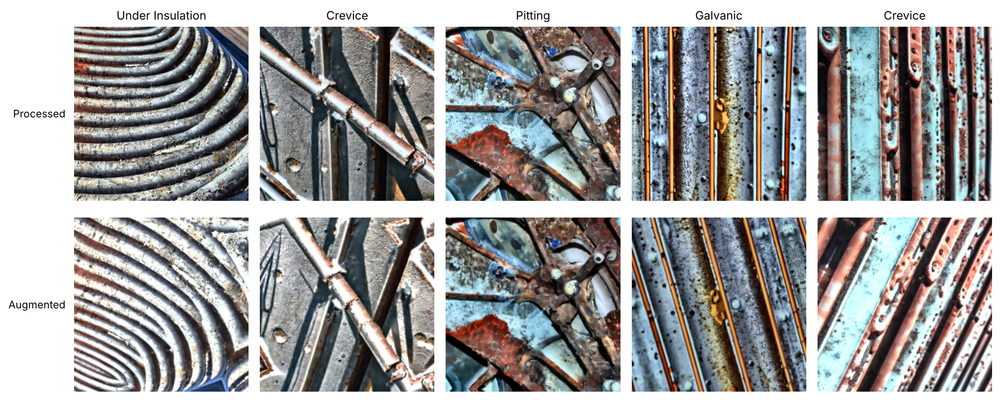

class_distribution.png


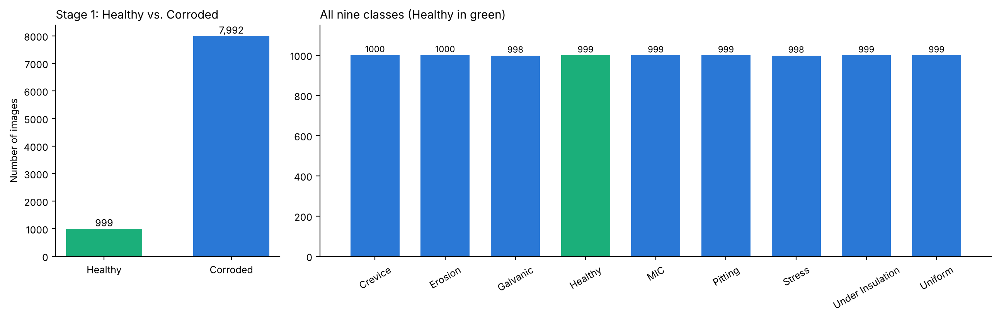

class_examples.png


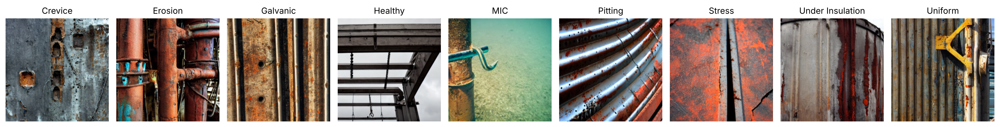

comparison.png


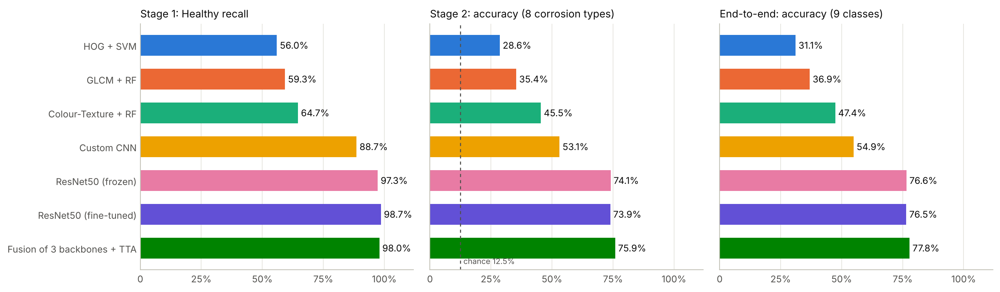

end_to_end_confusion.png


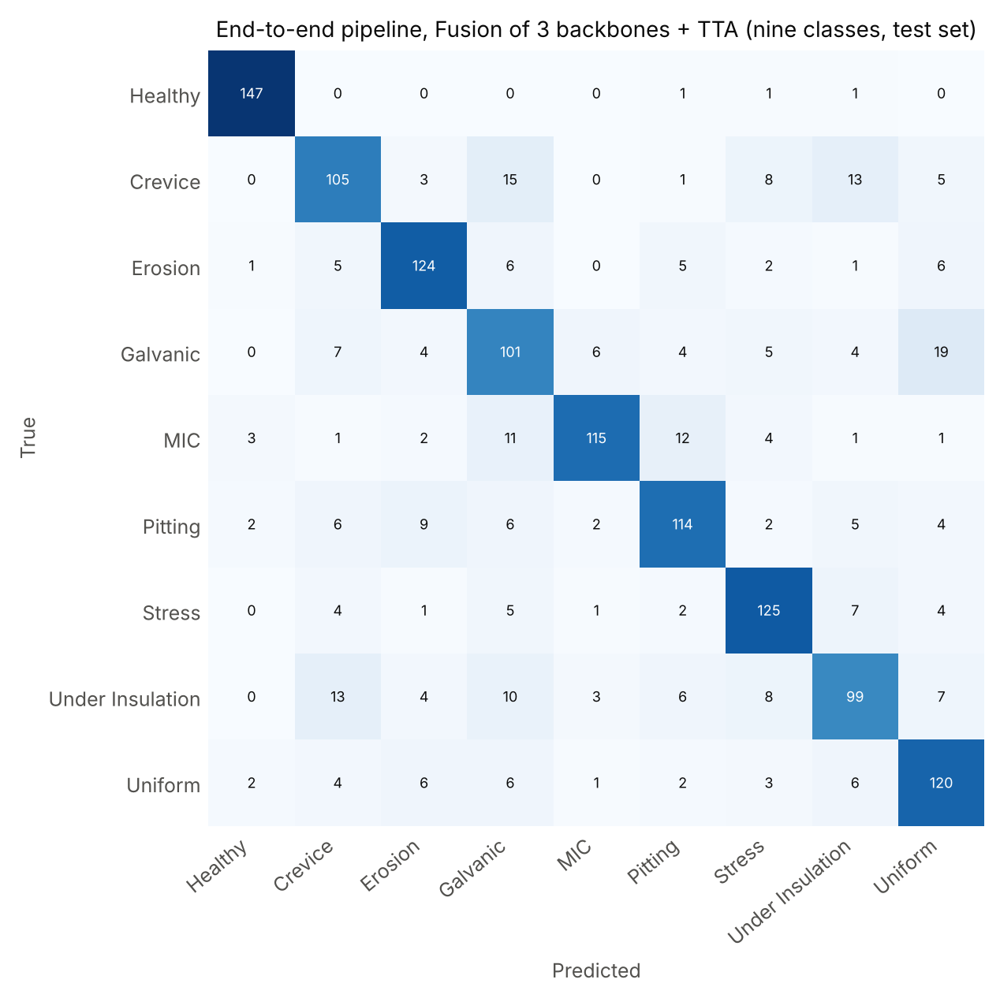

error_examples.png


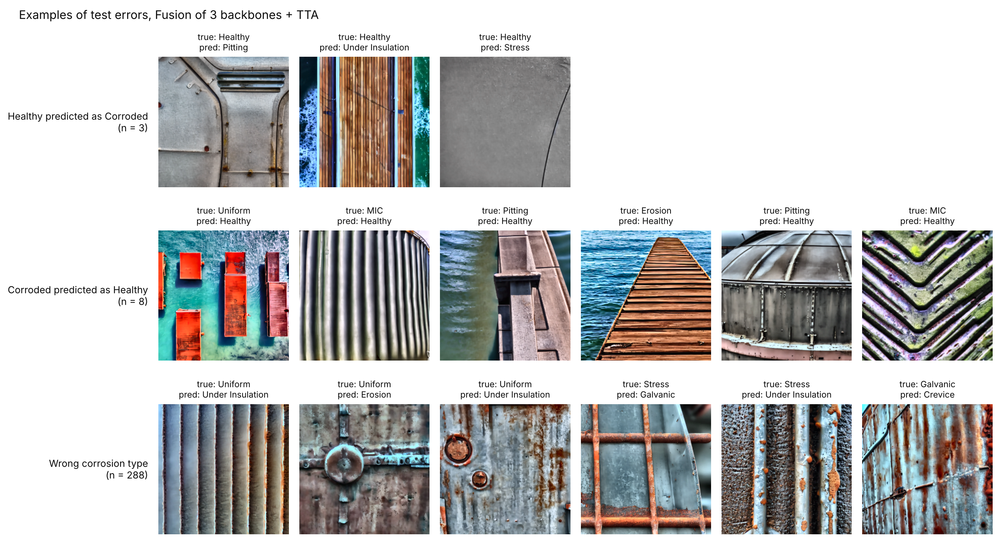

preprocessing_steps.png


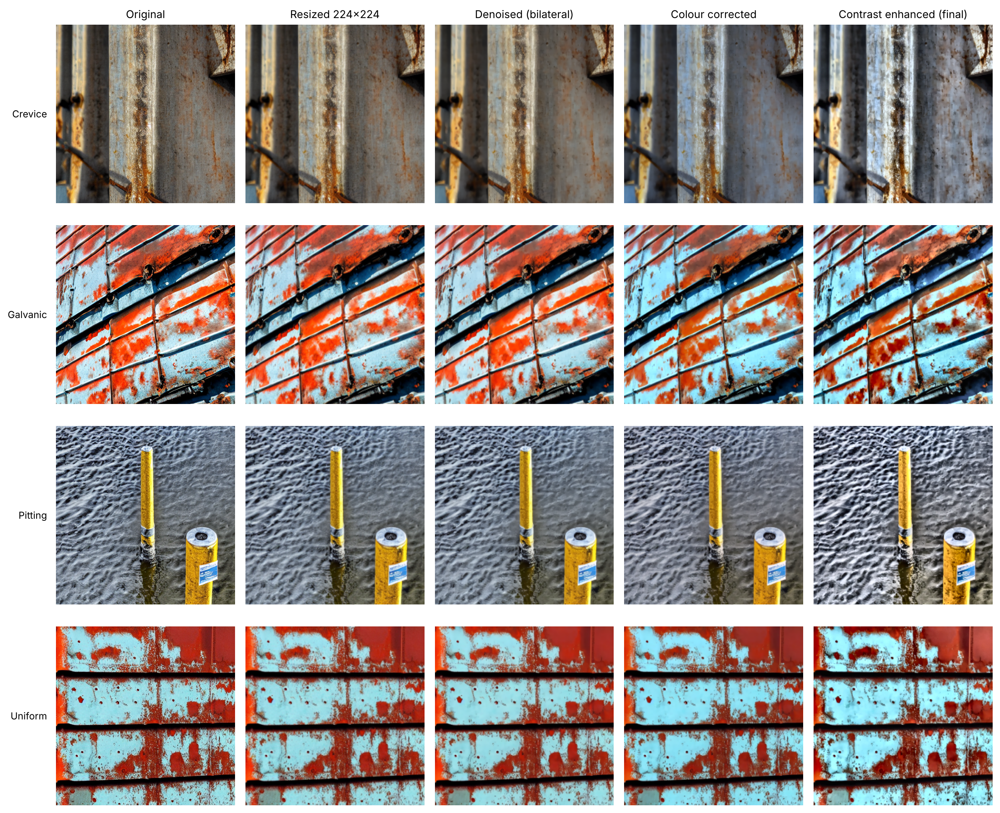

roc_threshold.png


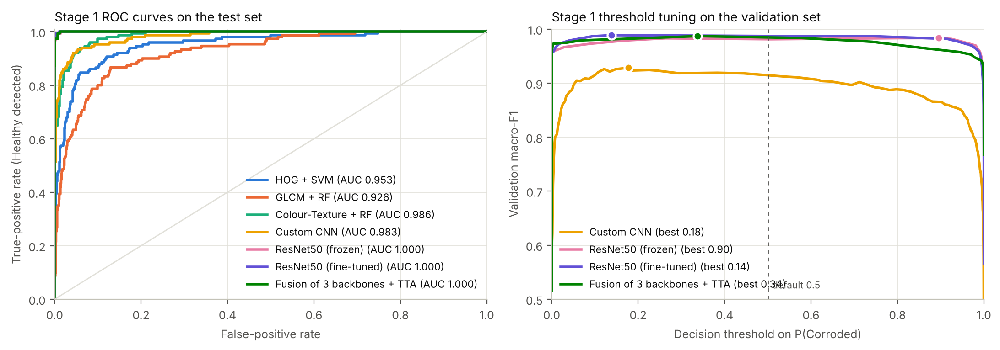

stage1_confusion.png


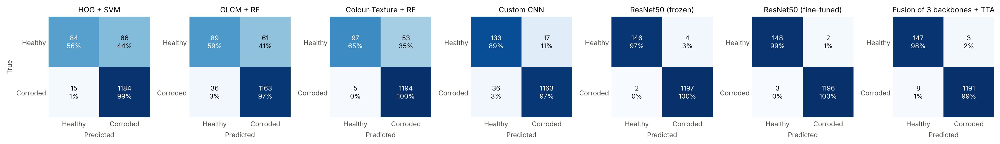

stage2_confusion.png


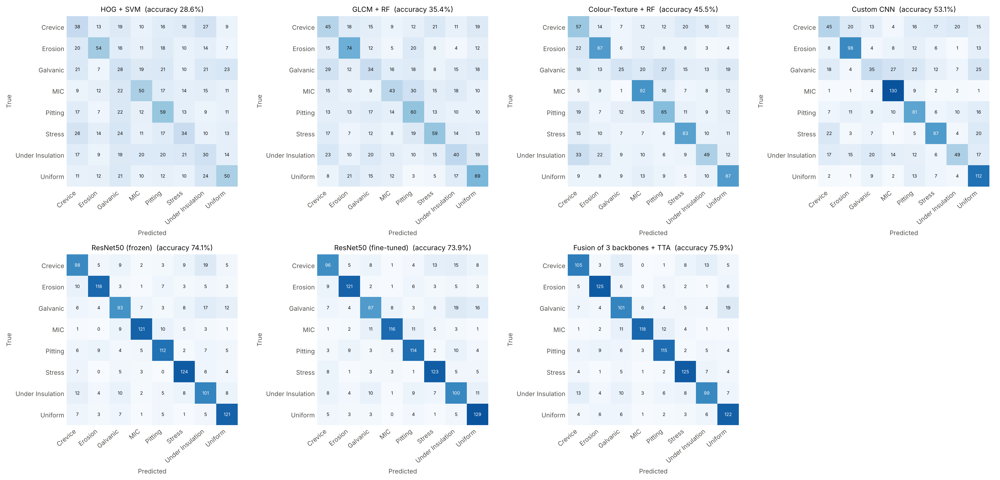

stage2_per_class_recall.png


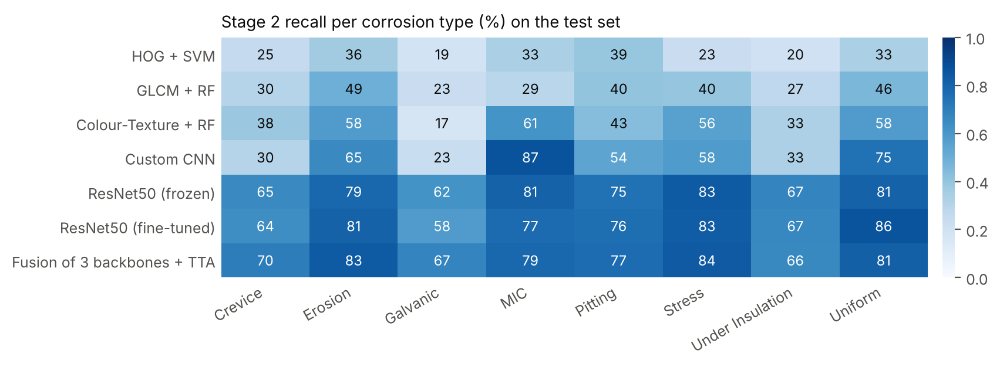

training_curves.png


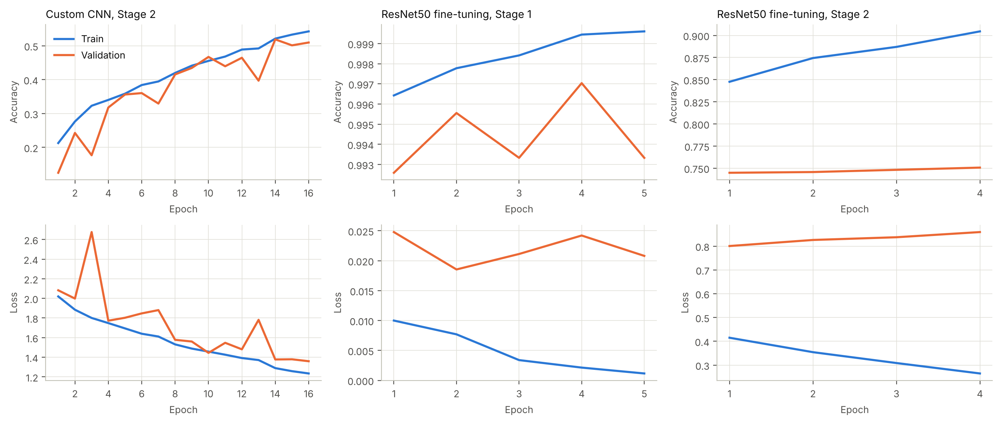

In [ ]:
SAVE = Path('/content/drive/MyDrive/CorroVision_Final_Results')
shutil.copytree(ROOT / 'outputs', SAVE, dirs_exist_ok=True)
print('Saved to', SAVE)
from IPython.display import Image, display
for f in sorted((ROOT / 'outputs' / 'figures').glob('*.png')):
    print(f.name); display(Image(str(f), width=900))